Data Science file used for chart creation

In [9]:
#import necessary modules
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline

In [10]:
#read files
df_30 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_30%VAX.csv")
df_40 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_40%VAX.csv")
df_50 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_50%VAX.csv")
df_60 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_60%VAX.csv")
df_70 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_70%VAX.csv")
df_80 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_80%VAX.csv")
df_90 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_90%VAX.csv")
df_95 = pd.read_csv("../Proof_Of_Concept_Dataset/measles_dataset_95%VAX.csv")


This code above to make the same change to all the dataframes is annoying, so I will make a function to make the same change to all of them.

In [11]:
dfslist = [df_30, df_40, df_50, df_60, df_70, df_80, df_90, df_95] #put all the dataframes into a list
def runonalldfs (method):
    """
    Function runs the passed pandas method on all of the dataframes in the "dfs" list.
        Necessary arguments:
            lambda df:
            index = 1
            inplace = True
    """
    for df in dfs:
        method(df)

This new function will make it easier to run pandas methods on all of the dataframes. The multiline string is there so that when I hover over the function in vscode, it reminds me of the arguments that need to be present for the function to run.

#delete a few columns
runonalldfs(lambda df: df.drop(["fps", "n_inf", "p_rad", "dm", "d_t_d", "d_prob"], axis=1, inplace = True))


In [12]:
dfs = pd.concat(dfslist)  # Combine all dataframes into one

Text(0.5, 1.0, '')

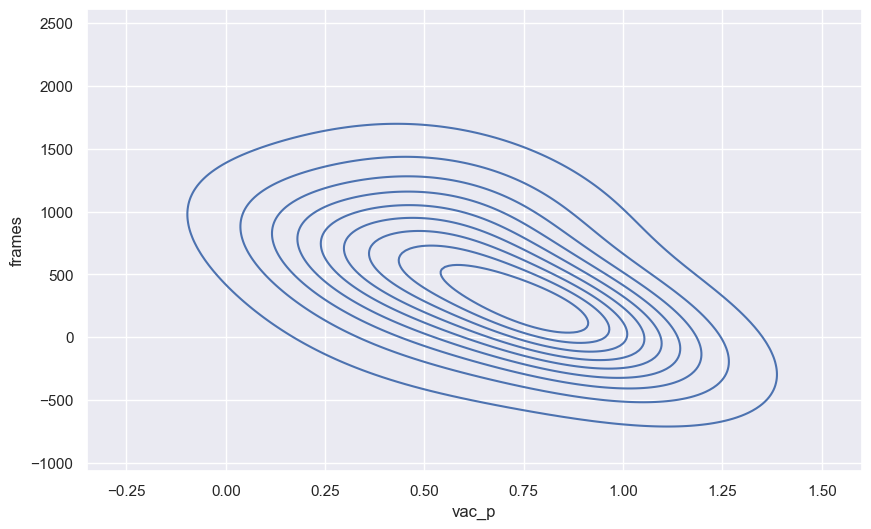

In [13]:
sns.set_theme(style='darkgrid')
plt.figure(figsize=(10,6))

fig=sns.kdeplot(
    data=dfs,
    x= "vac_p",
    y= "frames",
    fill = False,
    cumulative=False,
    bw_adjust=3
    )

plt.title("")

what was accidentally created here is a 3d frequency chart, as if shown from above. When i combined the dataframes, i accidentally created an array of dataframes and tried to plot it, making a 3d chart from the top.

![alt text](3dfrequencytable.png)

,fps,p_rad,days_r,dm,d_t_d,d_prob,h_i_t,vac_p,inf_p,i_rad,pop,t_inf,n_inf,imm,sus,dec,frames,seed
0,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,266,0,834,73,93,539,1
1,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,320,0,812,109,79,654,2
2,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,321,0,817,91,92,718,3
3,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,242,0,839,66,95,450,4
4,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,292,0,849,66,85,684,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,284,0,846,72,82,577,96
96,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,257,0,852,60,88,571,97
97,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,320,0,749,166,85,790,98
98,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,260,0,813,109,78,764,99


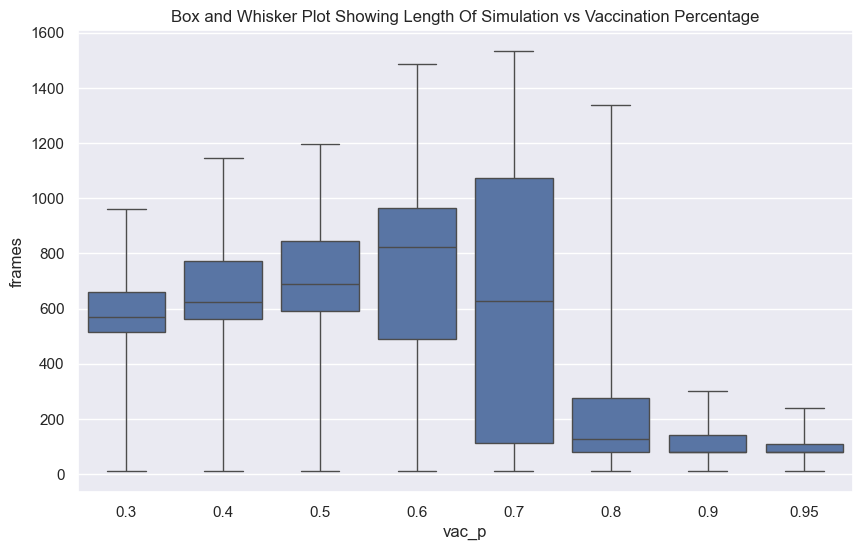

In [14]:
sns.set_theme(style='darkgrid')
plt.figure(figsize=(10,6))

fig=sns.boxplot(
    data=dfs,
    x= "vac_p",
    y= "frames",
    whis=(0,100)
    #fill = False,
    #cumulative=False,
    #bw_adjust=0.1
    )

plt.title("Box and Whisker Plot Showing Length Of Simulation vs Vaccination Percentage")
df_30 

C:\Users\abiga\AppData\Local\Temp\ipykernel_17176\1597425200.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  fig=sns.barplot(


,fps,p_rad,days_r,dm,d_t_d,d_prob,h_i_t,vac_p,inf_p,i_rad,pop,t_inf,n_inf,imm,sus,dec,frames,seed
0,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,266,0,834,73,93,539,1
1,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,320,0,812,109,79,654,2
2,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,321,0,817,91,92,718,3
3,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,242,0,839,66,95,450,4
4,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,292,0,849,66,85,684,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,284,0,846,72,82,577,96
96,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,257,0,852,60,88,571,97
97,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,320,0,749,166,85,790,98
98,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,260,0,813,109,78,764,99


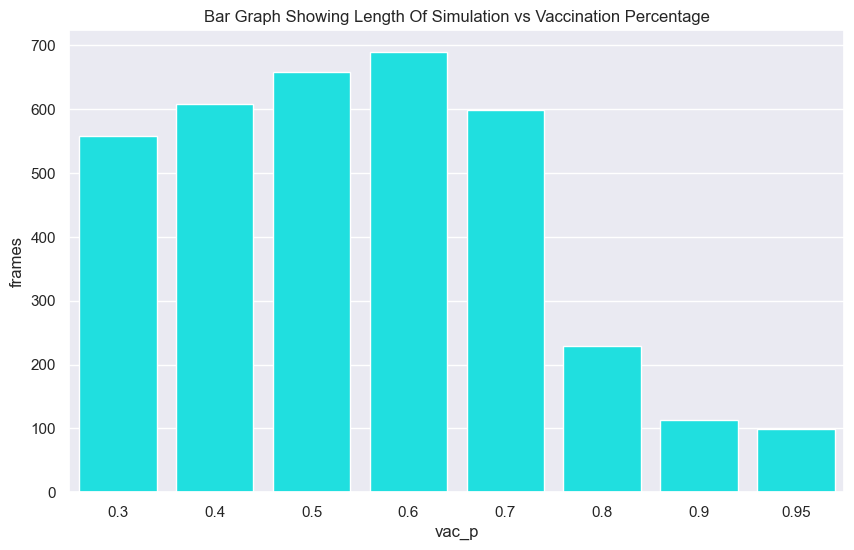

In [15]:
sns.set_theme(style='darkgrid')
plt.figure(figsize=(10,6))

fig=sns.barplot(
    data=dfs,
    x= "vac_p",
    y= "frames",
    color=(0,1,1),#divide rgb values by 255 because matplotlib uses 0-1 scale
    ci=None #this removes the error bars 
    )

plt.title("Bar Graph Showing Length Of Simulation vs Vaccination Percentage")
df_30 

C:\Users\abiga\AppData\Local\Temp\ipykernel_17176\134108302.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  fig=sns.barplot(


,fps,p_rad,days_r,dm,d_t_d,d_prob,h_i_t,vac_p,inf_p,i_rad,pop,t_inf,n_inf,imm,sus,dec,frames,seed
0,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,266,0,834,73,93,539,1
1,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,320,0,812,109,79,654,2
2,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,321,0,817,91,92,718,3
3,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,242,0,839,66,95,450,4
4,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,292,0,849,66,85,684,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,284,0,846,72,82,577,96
96,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,257,0,852,60,88,571,97
97,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,320,0,749,166,85,790,98
98,1000,5,80,10,10,0.02,0.93,0.3,0.97,5,1000,260,0,813,109,78,764,99


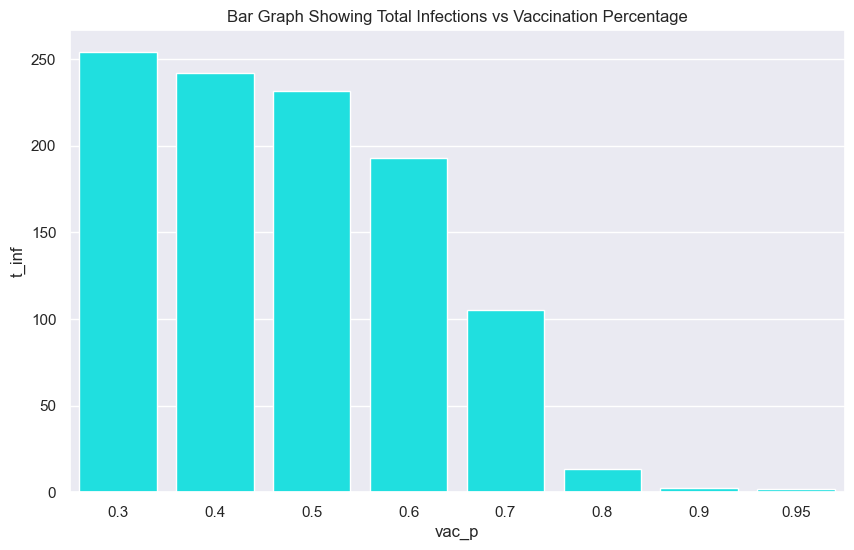

In [16]:
sns.set_theme(style='darkgrid')
plt.figure(figsize=(10,6))

fig=sns.barplot(
    data=dfs,
    x= "vac_p",
    y= "t_inf",
    color=(0,1,1),#divide rgb values by 255 because matplotlib uses 0-1 scale
    ci=None #this removes the error bars 
    )

plt.title("Bar Graph Showing Total Infections vs Vaccination Percentage")
df_30 

### This shows that vaccines are effective, which isn't a huge surprise. ###
